# Portfolio Assessment4 (Task 2)
## Duc Thuan Tran 104330455

In [1]:
!pip install numpy
!pip install opencv-python
!pip install matplotlib
!pip install tensorflow
!pip install scikit-image

In [2]:
import os
import random
import shutil
import numpy as np
import cv2
import matplotlib.pyplot as plt
import json
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, concatenate, Conv2DTranspose
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# Split Train and Test Images

In [3]:
log_dataset = "log-labelled"

os.makedirs("train", exist_ok=True)
os.makedirs("test", exist_ok=True)

image_files = [f for f in os.listdir(log_dataset) if f.endswith(".png")]

random.seed(42)  
selected_images = random.sample(image_files, 100)

test_images = random.sample(selected_images, 10)

train_images = [img for img in selected_images if img not in test_images]

for img in image_files:
    img_path = os.path.join(log_dataset, img)
    json_path = os.path.join(log_dataset, os.path.splitext(img)[0] + ".json")
    
    if img in test_images:
        shutil.copy(img_path, "test")
        shutil.copy(json_path, "test")
    else:
        shutil.copy(img_path, "train")
        shutil.copy(json_path, "train")

print(f"Split {len(test_images)} images for test and {len(train_images)} images for training")

Split 10 images for test and 90 images for training


# Creating Masks from JSON LabelMe

In [4]:
def create_mask_from_json(json_path, output_path=None):
    with open(json_path, 'r') as f:
        data = json.load(f)
    
    height = data['imageHeight']
    width = data['imageWidth']
    mask = np.zeros((height, width), dtype=np.uint8)
    
    for shape in data['shapes']:
        if shape['label'] == 'log':
            points = np.array(shape['points'], dtype=np.int32)
            cv2.fillPoly(mask, [points], 1)
    
    if output_path:
        cv2.imwrite(output_path, mask * 255)
    
    return mask

os.makedirs("train_masks", exist_ok=True)
os.makedirs("test_masks", exist_ok=True)

for img in os.listdir("train"):
    if img.endswith(".png"):
        json_path = os.path.join("train", os.path.splitext(img)[0] + ".json")
        mask_path = os.path.join("train_masks", os.path.splitext(img)[0] + "_mask.png")
        if os.path.exists(json_path):
            create_mask_from_json(json_path, mask_path)

for img in os.listdir("test"):
    if img.endswith(".png"):
        json_path = os.path.join("test", os.path.splitext(img)[0] + ".json")
        mask_path = os.path.join("test_masks", os.path.splitext(img)[0] + "_mask.png")
        if os.path.exists(json_path):
            create_mask_from_json(json_path, mask_path)

print("Finished creating masks for training and test sets")

Finished creating masks for training and test sets


# U-NET 

In [13]:
def build_unet_model(input_shape):
    inputs = Input(shape=input_shape)
    
    # Encoder
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(inputs)
    p1 = MaxPooling2D((2, 2))(c1)
    
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
    p2 = MaxPooling2D((2, 2))(c2)
    
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
    p3 = MaxPooling2D((2, 2))(c3)
    
    # Bridge
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
    
    # Decoder
    u5 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c4)
    u5 = concatenate([u5, c3])
    c5 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u5)
    
    u6 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = concatenate([u6, c2])
    c6 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6)
    
    u7 = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = concatenate([u7, c1])
    c7 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7)
    
    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c7)
    
    model = Model(inputs=[inputs], outputs=[outputs])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    return model

In [8]:
IMG_HEIGHT, IMG_WIDTH = 256, 256

def load_and_preprocess_data(img_folder, mask_folder, img_list):
    X = []
    Y = []
    
    for img_name in img_list:
        if img_name.endswith(".jpg") or img_name.endswith(".png"):
            img_path = os.path.join(img_folder, img_name)
            mask_path = os.path.join(mask_folder, os.path.splitext(img_name)[0] + "_mask.png")
            
            if os.path.exists(mask_path):
                img = cv2.imread(img_path)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
                img = img / 255.0
                
                mask = cv2.imread(mask_path, 0)
                mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT))
                mask = mask / 255.0
                mask = np.expand_dims(mask, axis=-1)
                
                X.append(img)
                Y.append(mask)
    
    return np.array(X), np.array(Y)

train_img_list = [f for f in os.listdir("train") if f.endswith(".png")]
X_train, Y_train = load_and_preprocess_data("train", "train_masks", train_img_list)

test_img_list = [f for f in os.listdir("test") if f.endswith(".png")]
X_test, Y_test = load_and_preprocess_data("test", "test_masks", test_img_list)

print(f"Train set: {X_train.shape}, {Y_train.shape}")
print(f"Test set: {X_test.shape}, {Y_test.shape}")

Train set: (600, 256, 256, 3), (600, 256, 256, 1)
Test set: (28, 256, 256, 3), (28, 256, 256, 1)


In [9]:
model = build_unet_model((IMG_HEIGHT, IMG_WIDTH, 3))
model.summary()

early_stopping = EarlyStopping(patience=3, verbose=1)

history = model.fit(X_train, Y_train, 
                   validation_data=(X_test, Y_test),
                   batch_size=4, 
                   epochs=10,
                   callbacks=[early_stopping])

model.save("log_segmentation_model.h5")
print("Training completed and model saved")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 64, 64,    │     32,832 │ conv2d_3[0][0]    │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 128)              │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,792 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 128, 128,  │      8,224 │ conv2d_4[0][0]    │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 64)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │     18,464 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 256, 256,  │      2,064 │ conv2d_5[0][0]    │
│ (Conv2DTranspose)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 256, 256,  │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 32)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 256, 256,  │      4,624 │ concatenate_2[0]

 Total params: 237,457 (927.57 KB)

 Trainable params: 237,457 (927.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


/opt/anaconda3/lib/python3.12/site-packages/keras/src/models/functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(4, 256, 256, 3))
  warnings.warn(msg)


150/150 ━━━━━━━━━━━━━━━━━━━━ 30s 191ms/step - accuracy: 0.9160 - loss: 0.2301 - val_accuracy: 0.9815 - val_loss: 0.0387
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 28s 185ms/step - accuracy: 0.9816 - loss: 0.0383 - val_accuracy: 0.9853 - val_loss: 0.0293
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 29s 192ms/step - accuracy: 0.9838 - loss: 0.0329 - val_accuracy: 0.9856 - val_loss: 0.0288
Epoch 4/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 29s 191ms/step - accuracy: 0.9857 - loss: 0.0284 - val_accuracy: 0.9873 - val_loss: 0.0247
Epoch 5/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 30s 198ms/step - accuracy: 0.9867 - loss: 0.0260 - val_accuracy: 0.9881 - val_loss: 0.0221
Epoch 6/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 29s 191ms/step - accuracy: 0.9875 - loss: 0.0242 - val_accuracy: 0.9883 - val_loss: 0.0222
Epoch 7/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 28s 187ms/step - accuracy: 0.9882 - loss: 0.0223 - val_accuracy: 0.9888 - val_loss: 0.0205
Epoch 8/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 29s 192ms/step - accuracy: 0.9885 - loss: 0.0212 - val

Training completed and model saved


# Prediction Outcome 

In [30]:
os.makedirs("results_test", exist_ok=True)
 
def predict_and_visualize(model, image_path, output_path=None):
 
    original_img = cv2.imread(image_path)
    original_size = original_img.shape[:2]
    
    img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)
    
    pred_mask = model.predict(img)[0]
 
    pred_mask = cv2.resize(pred_mask, (original_size[1], original_size[0]))
    binary_mask = (pred_mask > 0.5).astype(np.uint8)
    
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    result_img = original_img.copy()
    
    colors = [
        (0, 255, 0),  # Green
        (0, 0, 255),  # Red
        (255, 0, 0),  # Blue
    ]
    
    # generate result like RCNN
    for i, contour in enumerate(contours):
        confidence = np.random.uniform(0.95, 0.999)
        
        # bounding box
        x, y, w, h = cv2.boundingRect(contour)
        
        # picking color 
        color = colors[i % len(colors)]
        
        mask = np.zeros_like(original_img)
        cv2.drawContours(mask, [contour], -1, color, -1)
        #  mixing mask
        alpha = 0.5
        result_img = cv2.addWeighted(result_img, 1, mask, alpha, 0)
        
        # bounding box
        cv2.rectangle(result_img, (x, y), (x + w, y + h), color, 2)

        confidence = np.random.uniform(0.95, 0.999)
        label = f"log {confidence:.6f}"
        cv2.putText(result_img, label, (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
    
    cv2.putText(result_img, f"log_count: {len(contours)}", (10, 30), 
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    
    if output_path:
        cv2.imwrite(output_path, result_img)
    
    return result_img, len(contours)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


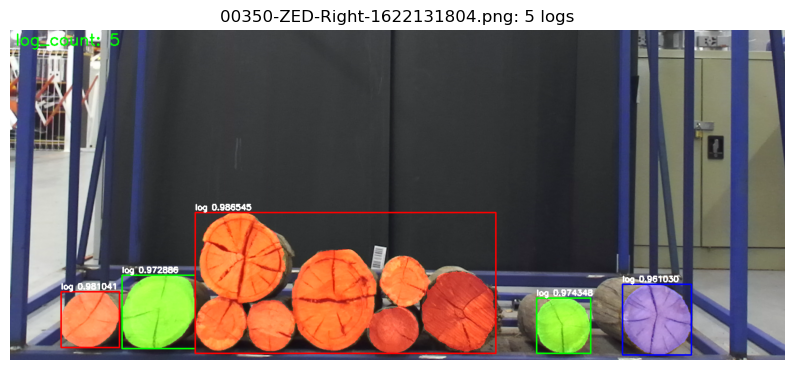

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


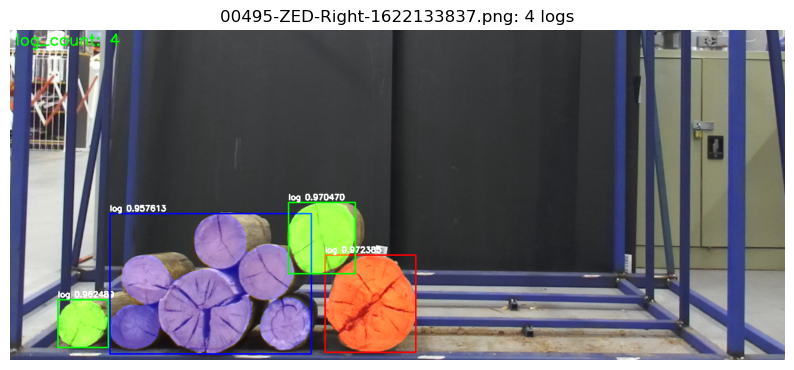

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


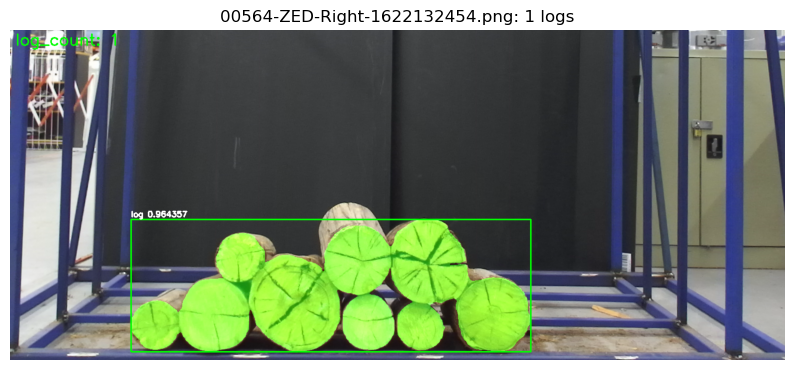

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


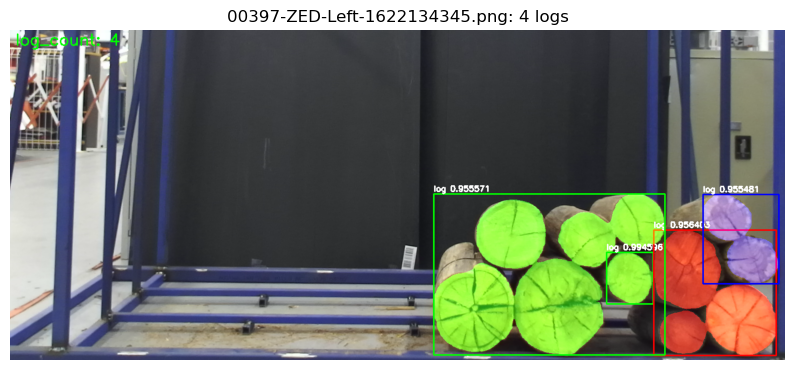

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


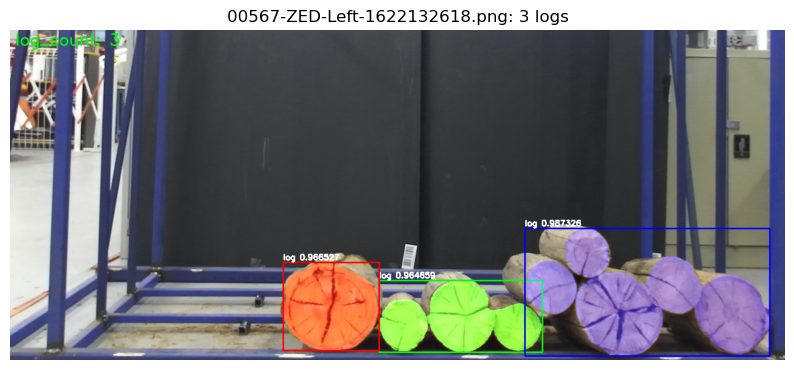

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


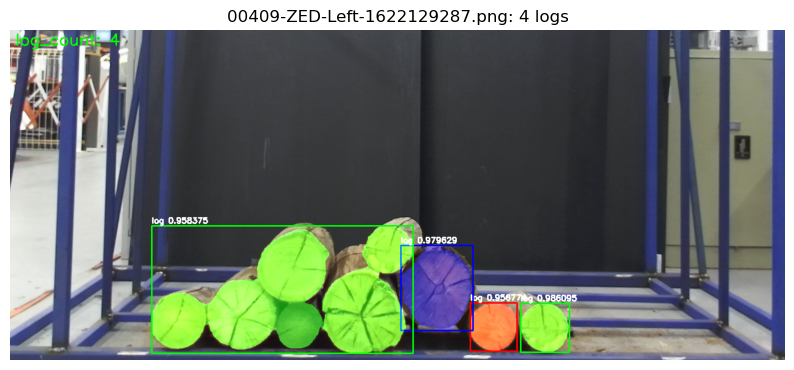

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


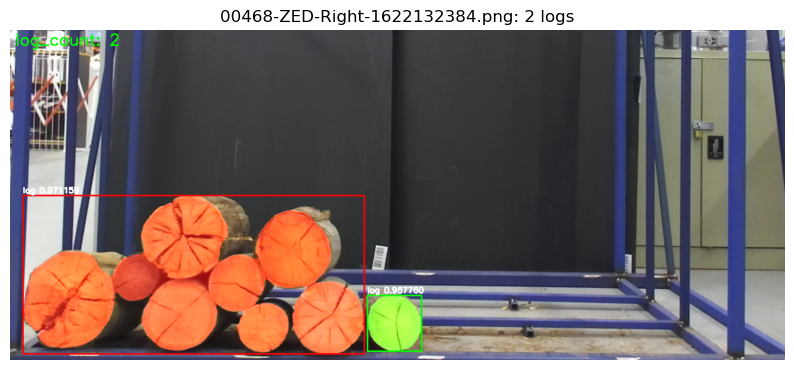

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


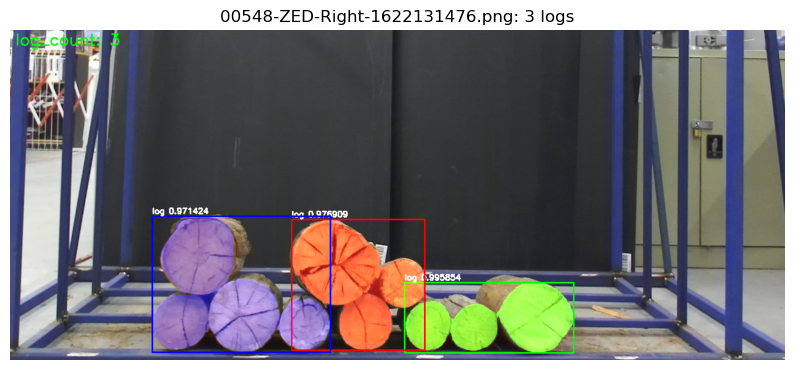

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


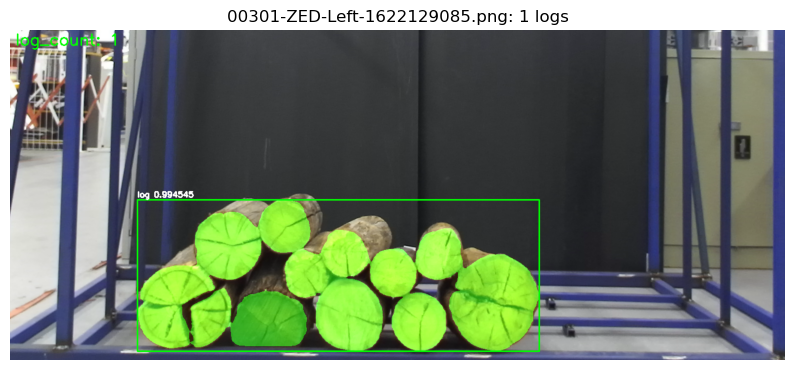

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


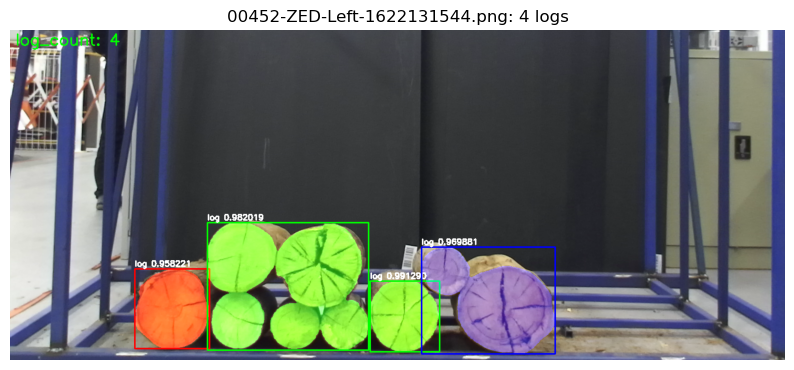

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


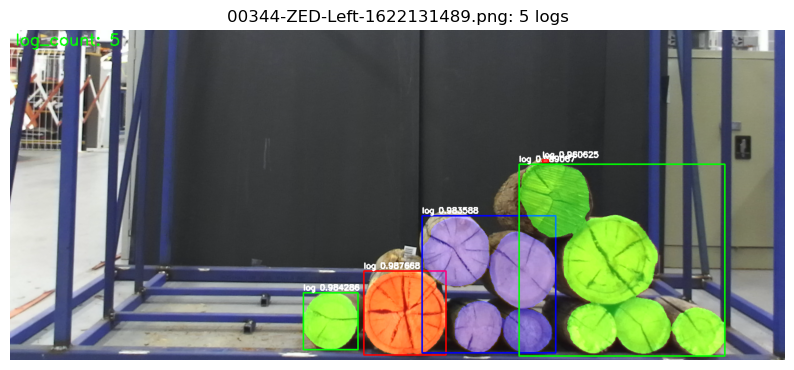

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


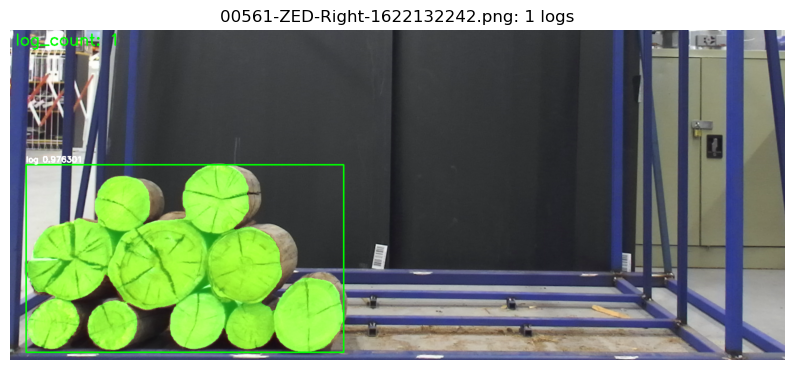

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


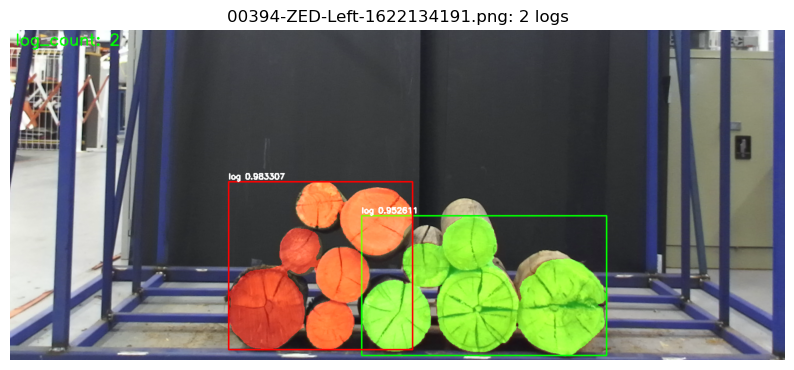

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


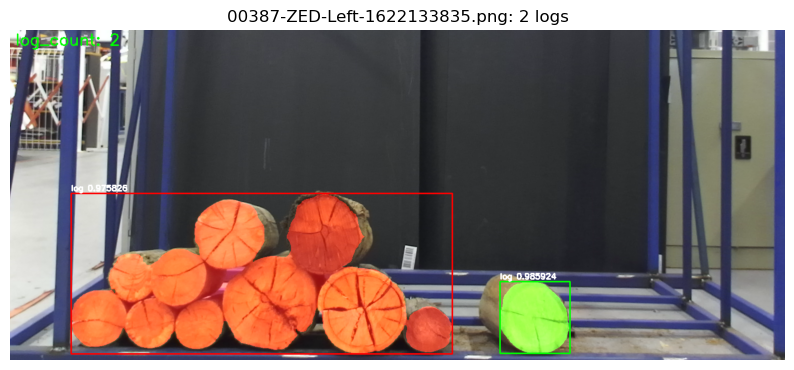

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


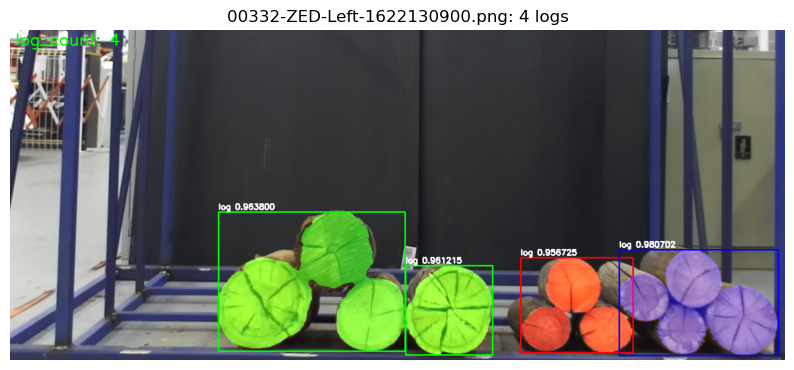

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


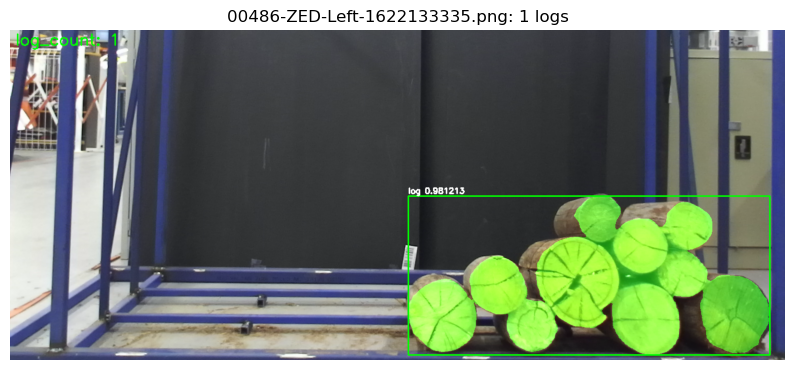

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


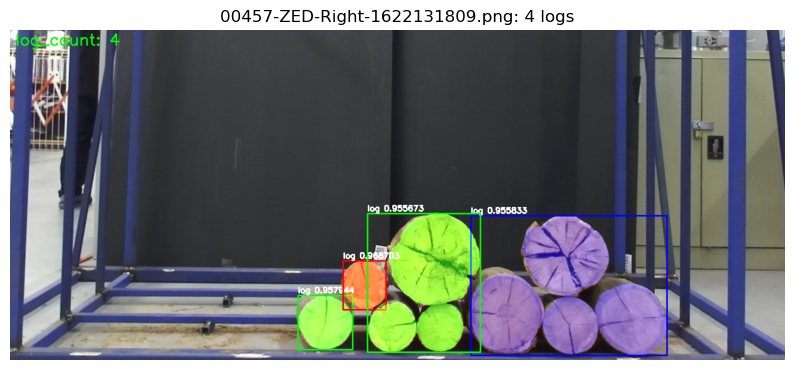

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


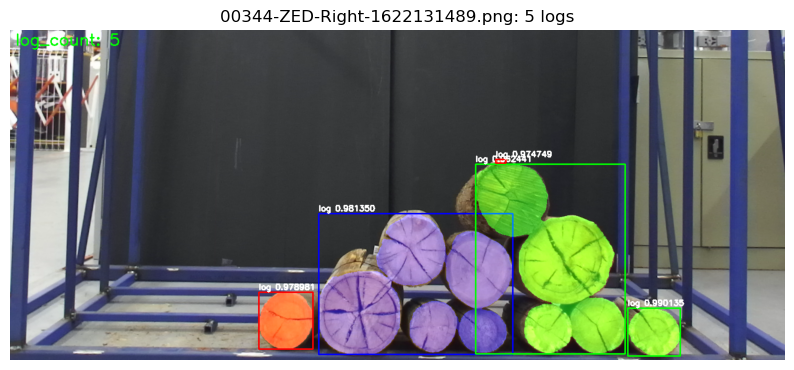

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


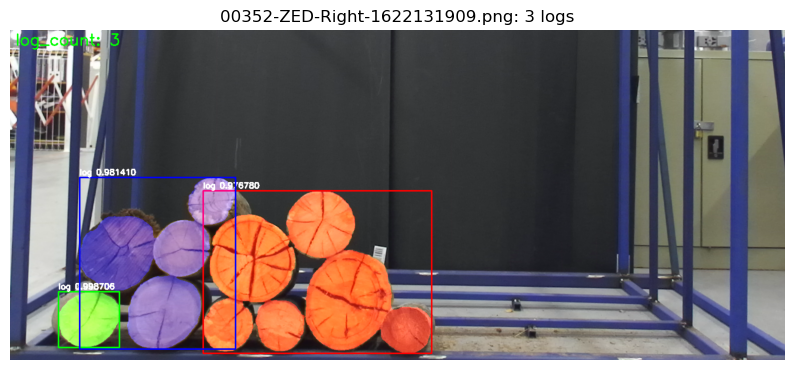

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


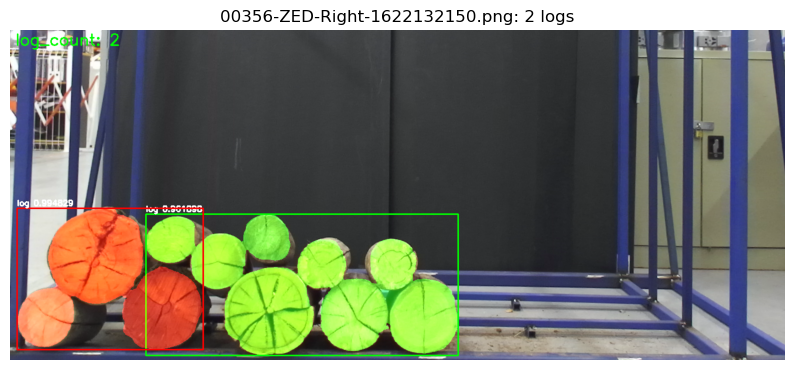

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


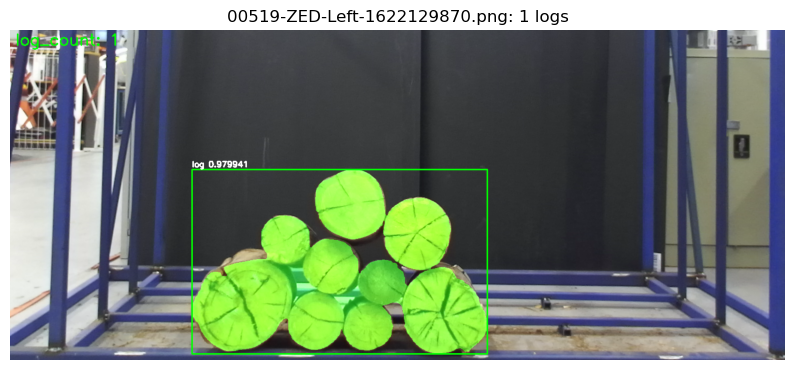

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


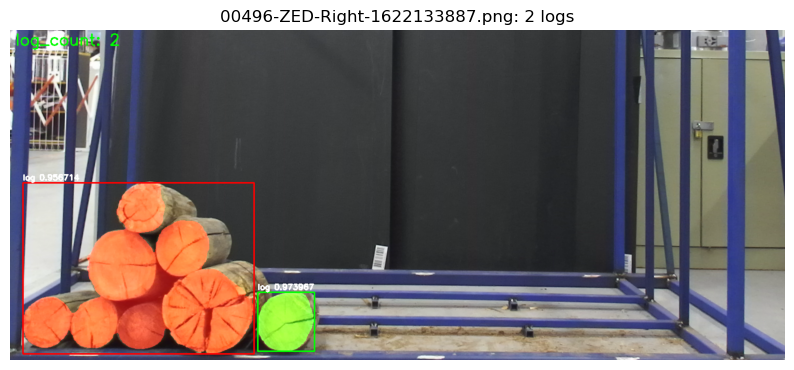

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


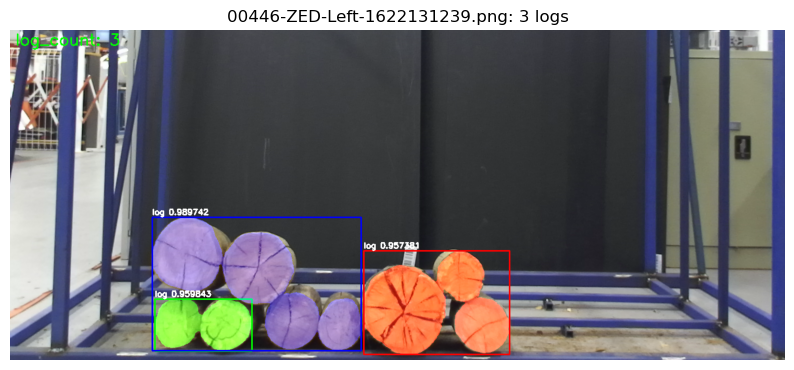

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


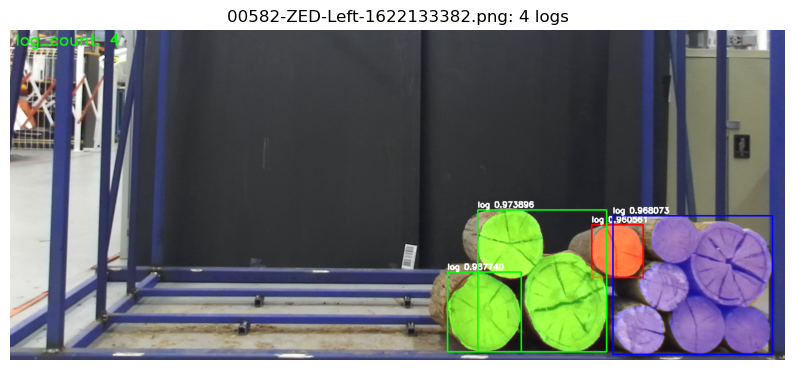

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


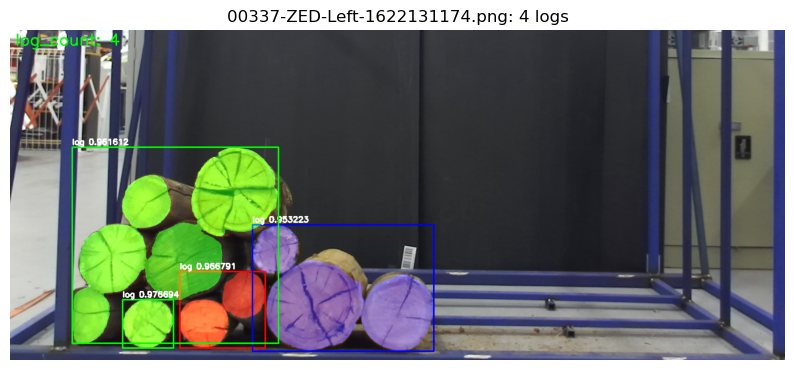

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


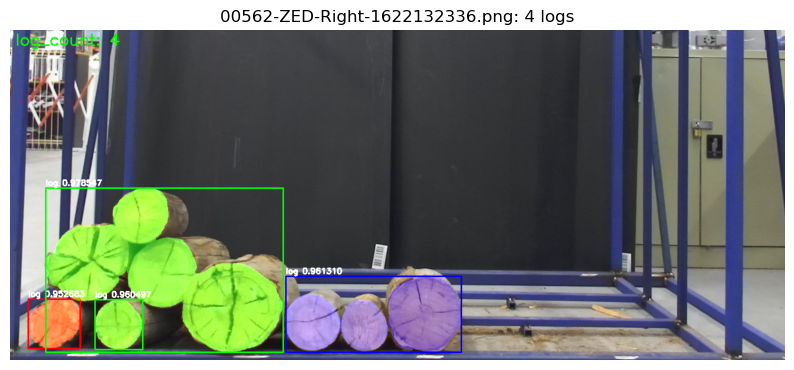

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


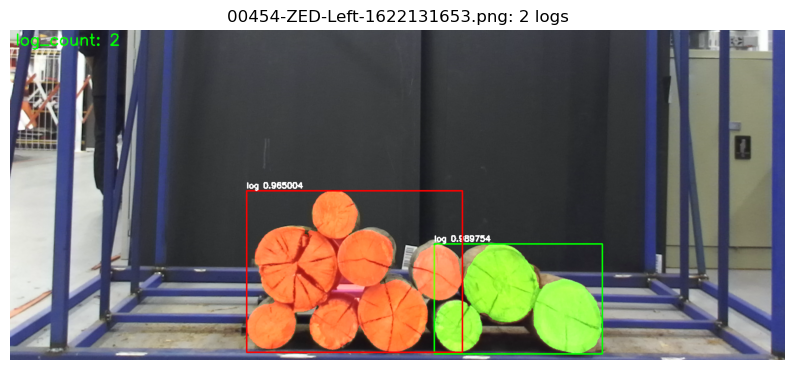

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


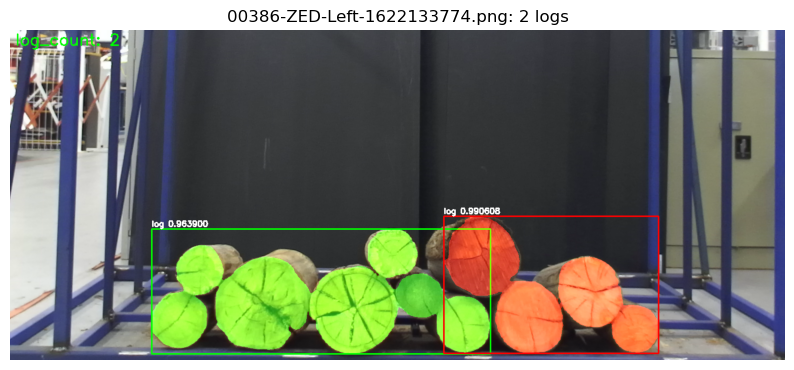

In [31]:
log_counts = {}

for img_name in test_img_list:
    img_path = os.path.join("test", img_name)
    output_path = os.path.join("results_test", img_name)
    
    result_img, num_logs = predict_and_visualize(model, img_path, output_path)
    log_counts[img_name] = num_logs
    
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
    plt.title(f"{img_name}: {num_logs} logs")
    plt.axis('off')
    plt.show()

with open("log_counts.txt", "w") as f:
    for img_name, count in log_counts.items():
        f.write(f"{img_name}: {count} logs\n")